In [279]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [280]:
df=pd.read_csv("Cleaned.csv")

In [281]:
df.head().T

,0,1,2,3,4
customerID,7590-VHVEG,5575-GNVDE,3668-QPYBK,7795-CFOCW,9237-HQITU
gender,Female,Male,Male,Male,Female
SeniorCitizen,0,0,0,0,0
Partner,Yes,No,No,No,No
Dependents,No,No,No,No,No
tenure,1,34,2,45,2
PhoneService,No,Yes,Yes,No,Yes
MultipleLines,No phone service,No,No,No phone service,No
InternetService,DSL,DSL,DSL,DSL,Fiber optic
OnlineSecurity,No,Yes,Yes,Yes,No


In [282]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [283]:
y=df["Churn"]
x=df.drop(columns=["Churn","customerID"])

In [284]:
x.shape,y.shape

((7043, 19), (7043,))

In [285]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42,stratify=y)

In [286]:
num_col=X_train.select_dtypes(include=["int64","float64"]).columns
num_col

Index(['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges'], dtype='str')

In [287]:
cat_col=X_train.select_dtypes(include=["str"]).columns
cat_col

Index(['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines',
       'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
       'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract',
       'PaperlessBilling', 'PaymentMethod'],
      dtype='str')

In [288]:
df[cat_col].nunique()

gender              2
Partner             2
Dependents          2
PhoneService        2
MultipleLines       3
InternetService     3
OnlineSecurity      3
OnlineBackup        3
DeviceProtection    3
TechSupport         3
StreamingTV         3
StreamingMovies     3
Contract            3
PaperlessBilling    2
PaymentMethod       4
dtype: int64

In [289]:
from sklearn.preprocessing import StandardScaler

scaler=StandardScaler()
X_train_scaled=scaler.fit_transform(X_train[num_col])
X_test_scaled=scaler.transform(X_test[num_col])

In [290]:
from sklearn.preprocessing import OneHotEncoder
encoder=OneHotEncoder(sparse_output=False,drop='first')
X_train_encoded=encoder.fit_transform(X_train[cat_col])
X_test_encoded=encoder.transform(X_test[cat_col])

In [291]:
X_train_final=pd.concat([pd.DataFrame(X_train_scaled, columns=num_col), pd.DataFrame(X_train_encoded, columns=encoder.get_feature_names_out(cat_col))], axis=1)
X_test_final=pd.concat([pd.DataFrame(X_test_scaled, columns=num_col), pd.DataFrame(X_test_encoded, columns=encoder.get_feature_names_out(cat_col))], axis=1)

In [292]:
from sklearn.linear_model import LogisticRegression
lr=LogisticRegression(max_iter=1000)
lr.fit(X_train_final,y_train)



,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

In [293]:
y_pred1=lr.predict(X_test_final)
y_pred1


array([0, 1, 0, ..., 0, 0, 0], shape=(1409,))

In [294]:
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score
a1=accuracy_score(y_test,y_pred1)
b1=precision_score(y_test,y_pred1)
c1=recall_score(y_test,y_pred1)
d1=f1_score(y_test,y_pred1)


print("Accuracy :", a1)
print("Precision:", b1)
print("Recall   :", c1)
print("F1 Score :", d1)

Accuracy : 0.8069552874378992
Precision: 0.660377358490566
Recall   : 0.5614973262032086
F1 Score : 0.6069364161849711


Text(50.83333333333333, 0.5, 'Actual')

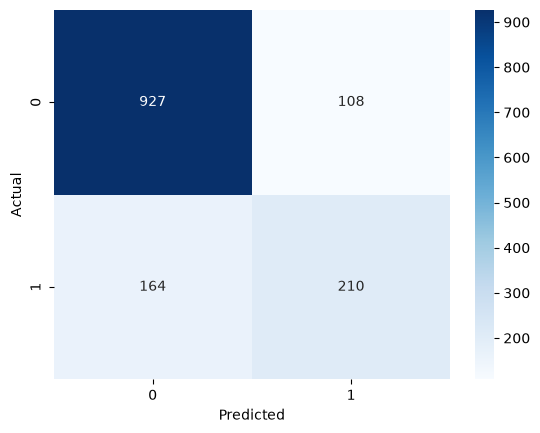

In [295]:
from sklearn.metrics import confusion_matrix
cm=confusion_matrix(y_test,y_pred1)
sns.heatmap(cm,annot=True,cmap="Blues",fmt="d")
plt.xlabel("Predicted")
plt.ylabel("Actual")

In [296]:
from sklearn.ensemble import RandomForestClassifier
rf=RandomForestClassifier(n_estimators=100,random_state=41,n_jobs=-1)
rf.fit(X_train_final,y_train)
y_pred2=rf.predict(X_test_final)
y_pred2


array([0, 1, 0, ..., 0, 0, 0], shape=(1409,))

In [297]:
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score
a2=accuracy_score(y_test,y_pred2)
b2=precision_score(y_test,y_pred2)
c2=recall_score(y_test,y_pred2)
d2=f1_score(y_test,y_pred2)


print("Accuracy :", a2)
print("Precision:", b2)
print("Recall   :", c2)
print("F1 Score :", d2)

Accuracy : 0.7920511000709723
Precision: 0.6382252559726962
Recall   : 0.5
F1 Score : 0.56071964017991


Text(50.83333333333333, 0.5, 'Actual')

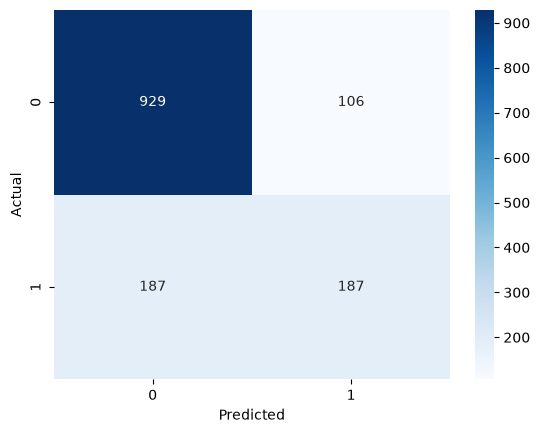

In [298]:
from sklearn.metrics import confusion_matrix
cm=confusion_matrix(y_test,y_pred2)
sns.heatmap(cm,annot=True,cmap="Blues",fmt="d")
plt.xlabel("Predicted")
plt.ylabel("Actual")

In [299]:
from xgboost import XGBClassifier
xgb=XGBClassifier(n_estimators=100,random_state=42,n_jobs=-1)
xgb.fit(X_train_final,y_train)
y_pred3=xgb.predict(X_test_final)
y_pred3

array([0, 1, 0, ..., 0, 0, 0], shape=(1409,))

In [300]:
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score
a3=accuracy_score(y_test,y_pred3)
b3=precision_score(y_test,y_pred3)
c3=recall_score(y_test,y_pred3)
d3=f1_score(y_test,y_pred3)


print("Accuracy :", a3)
print("Precision:", b3)
print("Recall   :", c3)
print("F1 Score :", d3)

Accuracy : 0.7764371894960965
Precision: 0.5891238670694864
Recall   : 0.5213903743315508
F1 Score : 0.5531914893617021


Text(50.83333333333333, 0.5, 'Actual')

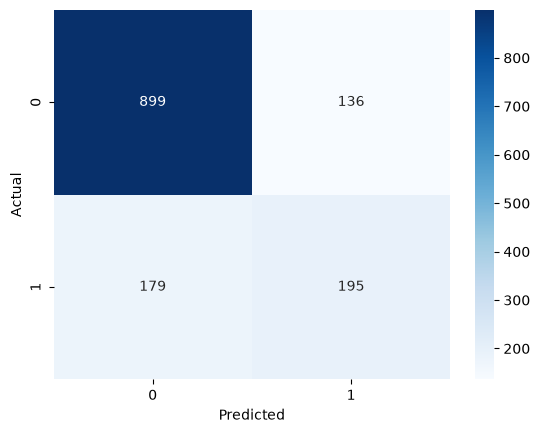

In [301]:
from sklearn.metrics import confusion_matrix
cm=confusion_matrix(y_test,y_pred3)
sns.heatmap(cm,annot=True,cmap="Blues",fmt="d")
plt.xlabel("Predicted")
plt.ylabel("Actual")

###MLP :-

In [302]:
import tensorflow
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense

In [303]:
model = Sequential([Dense(64, activation="relu", input_shape=(X_train_final.shape[1],)),
                    Dense(32, activation="relu"),Dense(1, activation="sigmoid")])

model.compile(
    optimizer="adam",loss="binary_crossentropy",metrics=["accuracy"]
)

history = model.fit(
    X_train_final.astype("float32"),y_train,epochs=50,batch_size=32,validation_split=0.2
)

Epoch 1/50


c:\Users\Devansh Chauhan\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


141/141 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7229 - loss: 0.5144 - val_accuracy: 0.7941 - val_loss: 0.4506
Epoch 2/50
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8010 - loss: 0.4214 - val_accuracy: 0.7862 - val_loss: 0.4446
Epoch 3/50
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8028 - loss: 0.4130 - val_accuracy: 0.7977 - val_loss: 0.4392
Epoch 4/50
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8101 - loss: 0.4092 - val_accuracy: 0.7906 - val_loss: 0.4397
Epoch 5/50
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8094 - loss: 0.4060 - val_accuracy: 0.7862 - val_loss: 0.4388
Epoch 6/50
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8094 - loss: 0.4048 - val_accuracy: 0.7844 - val_loss: 0.4417
Epoch 7/50
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8127 - loss: 0.4024 - val_accuracy: 0.7941 - val_loss: 0.4387
Epoch 8/50
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8163 - loss: 0.3977 - val_accuracy: 0.7924 - val_

In [304]:
y_prex=model.predict(X_test_final)
y_prex

45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


array([[0.03063417],
       [0.9420469 ],
       [0.00410635],
       ...,
       [0.11884786],
       [0.00560498],
       [0.00235493]], shape=(1409, 1), dtype=float32)

In [305]:
y_pred4=(y_prex>0.5).astype(int)
y_pred4

array([[0],
       [1],
       [0],
       ...,
       [0],
       [0],
       [0]], shape=(1409, 1))

In [306]:
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score
a4=accuracy_score(y_test,y_pred3)
b4=precision_score(y_test,y_pred3)
c4=recall_score(y_test,y_pred3)
d4=f1_score(y_test,y_pred3)


print("Accuracy :", a4)
print("Precision:", b4)
print("Recall   :", c4)
print("F1 Score :", d4)

Accuracy : 0.7764371894960965
Precision: 0.5891238670694864
Recall   : 0.5213903743315508
F1 Score : 0.5531914893617021


Text(50.83333333333333, 0.5, 'Actual')

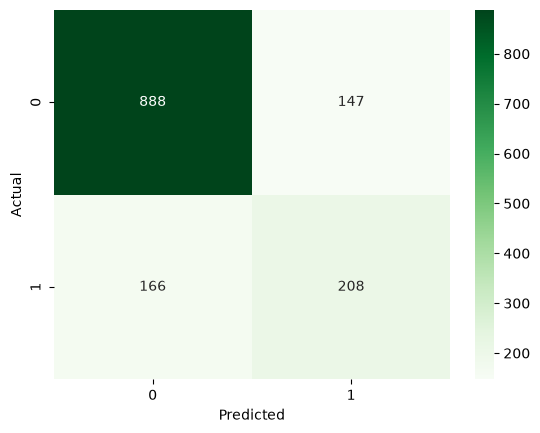

In [307]:
from sklearn.metrics import confusion_matrix
cm=confusion_matrix(y_test,y_pred4)
sns.heatmap(cm,annot=True,cmap="Greens",fmt="d")
plt.xlabel("Predicted")
plt.ylabel("Actual")

In [308]:
compare=pd.DataFrame({"Models":["Logisic_regression","Random_Forest_Classifier","XG_Boost_Classifier","ANN"],"Accuracy":[a1,a2,a3,a4],"Precision":[b1,b2,b3,b4],"Recall":[c1,c2,c3,c4],"F1_Score":[d1,d2,d3,d4]})
compare

,Models,Accuracy,Precision,Recall,F1_Score
0,Logisic_regression,0.806955,0.660377,0.561497,0.606936
1,Random_Forest_Classifier,0.792051,0.638225,0.500000,0.560720
2,XG_Boost_Classifier,0.776437,0.589124,0.521390,0.553191
3,ANN,0.776437,0.589124,0.521390,0.553191


In [309]:
model.save("ANN.keras")

In [310]:
import joblib
from pathlib import Path

model_dir = Path("model")
model_dir.mkdir(exist_ok=True)

joblib.dump(scaler, model_dir / "scaler.pkl")
joblib.dump(encoder, model_dir / "encoder.pkl")
joblib.dump({
    "numeric_columns": list(num_col),
    "categorical_columns": list(cat_col),
}, model_dir / "preprocessing_columns.pkl")
joblib.dump(lr, model_dir / "Logestic.pkl")
print("Saved model and preprocessing files to model/")

Saved model and preprocessing files to model/
